# Where Should the Wellbeing Budget Go? Testing Four Burnout Interventions
**Assessment 3 - Data Analytics Portfolio** · Author: Md Wasiq Dayem Minhazul Kabir Abir

**Decision-maker:** Chief People Officer (CPO) of a large multi-industry employer
**Decision:** The 2027 wellbeing budget can fund only some of four proposed burnout interventions. Which should be funded, and for whom?

**Dataset:** *Remote Work & Health Impact Survey 2025* (Kaggle, P. Puri), 3,157 employees surveyed in June 2025.

### How to reproduce
1. Put `post_pandemic_remote_work_health_impact_2025.csv` in the same folder as this notebook.
2. Python 3.10+ with `pandas numpy scipy statsmodels matplotlib seaborn scikit-learn`.
3. *Kernel -> Restart & Run All*. Outputs: `outputs/clean_remote_work.csv` (Power BI source) and `outputs/fig*.png` (report charts).

### The four proposals and the assumption each one rests on
Each proposal only pays off if its assumption holds. The analysis tests every assumption against the data before any money is committed.

| Proposal | Assumption it rests on | Test in this notebook |
|---|---|---|
| A. Ergonomic home-office stipend | Physical pain is higher for home-based staff and is linked to burnout | Section 5: chi-square, Kruskal-Wallis |
| B. Expanded mental-health support (EAP) as a burnout measure | Staff with a reported mental-health condition burn out more | Section 6: chi-square |
| C. Workload caps (limit weekly hours) | Long hours or poor work-life balance drive burnout | Section 7: chi-square, Spearman |
| D. Connection programme for remote/hybrid staff | Burnout and isolation concentrate in staff who work away from the office | Section 8: chi-square, Kruskal-Wallis |
| All four together | Which lever still matters when the others are held constant? | Section 9: multivariable logistic regression |

In [1]:
# --- Setup -------------------------------------------------------------------
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.proportion import proportion_confint
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 30)
os.makedirs("outputs", exist_ok=True)
RESULTS = {}            # key numbers quoted in the report, saved at the end for cross-checking

# Fixed colour per arrangement, used in every chart (colour follows the entity)
ORDER = ["Onsite", "Hybrid", "Remote"]
COLORS = {"Onsite": "#2a78d6", "Hybrid": "#eb6834", "Remote": "#1baf7a"}
INK, MUTED, GRID, PALE = "#0b0b0b", "#52514e", "#e4e3df", "#c9c8c3"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 200,
    "savefig.bbox": "tight",
})

def cramers_v(a, b, data):
    # Chi-square test of independence + Cramer's V effect size for two categorical columns
    ct = pd.crosstab(data[a], data[b])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), chi2, p, dof

## 1. Load and audit the raw data

In [2]:
raw = pd.read_csv("post_pandemic_remote_work_health_impact_2025.csv")
print("Shape:", raw.shape)
print("Duplicate rows:", raw.duplicated().sum())
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
audit

Shape: (3157, 14)
Duplicate rows: 0


,dtype,missing,missing_%,unique
Survey_Date,object,0,0.0,26
Age,int64,0,0.0,44
Gender,object,0,0.0,4
Region,object,0,0.0,6
Industry,object,0,0.0,9
Job_Role,object,0,0.0,24
Work_Arrangement,object,0,0.0,3
Hours_Per_Week,int64,0,0.0,31
Mental_Health_Status,object,799,25.3,6
Burnout_Level,object,0,0.0,3


In [3]:
# Range checks on numeric fields - flags impossible values (none expected)
raw.describe().T[["min", "max", "mean"]].round(2)

,min,max,mean
Age,22.0,65.0,43.73
Hours_Per_Week,35.0,65.0,49.90
Work_Life_Balance_Score,1.0,5.0,3.00
Social_Isolation_Score,1.0,5.0,2.70


In [4]:
# Categories of the fields we will analyse
for col in ["Work_Arrangement", "Burnout_Level", "Mental_Health_Status", "Salary_Range"]:
    print(col, raw[col].value_counts(dropna=False).to_dict(), "\n")
print("Physical issues (split):", raw["Physical_Health_Issues"].str.split("; ").explode().value_counts(dropna=False).to_dict())

Work_Arrangement {'Onsite': 1562, 'Hybrid': 1007, 'Remote': 588} 

Burnout_Level {'Medium': 1366, 'High': 1046, 'Low': 745} 

Mental_Health_Status {nan: 799, 'PTSD': 423, 'Anxiety': 394, 'Burnout': 392, 'Depression': 386, 'ADHD': 385, 'Stress Disorder': 378} 

Salary_Range {'$60K-80K': 1014, '$80K-100K': 964, '$40K-60K': 510, '$100K-120K': 459, '$120K+': 210} 

Physical issues (split): {'Eye Strain': 1604, 'Back Pain': 1563, 'Shoulder Pain': 1507, 'Neck Pain': 798, 'Wrist Pain': 467, nan: 280}


**Audit findings.** No duplicate rows and no out-of-range values. Only two fields have blanks:
`Mental_Health_Status` (799, 25%) and `Physical_Health_Issues` (280, 9%). Every other row in those
fields lists a condition, so a blank is best read as *"no condition reported"* rather than missing data.
Dropping these rows would remove a quarter of the sample and bias it toward people with a condition -
the very comparison proposals A and B depend on - so they are **recoded, not dropped**.

## 2. Data preparation

In [5]:
df = raw.copy()

# 2.1 Blanks in health fields mean "none reported" (see audit note above)
df["Mental_Health_Status"] = df["Mental_Health_Status"].fillna("None reported")
df["Physical_Health_Issues"] = df["Physical_Health_Issues"].fillna("None reported")

# 2.2 Ordered categories so tables and charts sort logically
df["Work_Arrangement"] = pd.Categorical(df["Work_Arrangement"], ORDER, ordered=True)
df["Burnout_Level"] = pd.Categorical(df["Burnout_Level"], ["Low", "Medium", "High"], ordered=True)
SAL = ["$40K-60K", "$60K-80K", "$80K-100K", "$100K-120K", "$120K+"]
df["Salary_Range"] = pd.Categorical(df["Salary_Range"], SAL, ordered=True)

# 2.3 Outcome and grouping variables
df["Burnout_Score"] = df["Burnout_Level"].cat.codes + 1                  # 1 = Low ... 3 = High
df["High_Burnout"] = (df["Burnout_Level"] == "High").astype(int)          # the outcome the budget targets
df["High_Isolation"] = (df["Social_Isolation_Score"] >= 4).astype(int)    # top two scale points
df["Age_Band"] = pd.cut(df["Age"], [21, 30, 40, 50, 65], labels=["22-30", "31-40", "41-50", "51-65"])
df["Hours_Band"] = pd.cut(df["Hours_Per_Week"], [34, 40, 50, 60, 65], labels=["35-40", "41-50", "51-60", "61-65"])

# 2.4 Proposal A inputs: physical issues are stored as "A; B" text -> count, band and one flag per issue
issues = df["Physical_Health_Issues"].str.split("; ")
df["Physical_Issue_Count"] = issues.apply(lambda x: 0 if x == ["None reported"] else len(x))
df["Issue_Band"] = df["Physical_Issue_Count"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
for issue in ["Eye Strain", "Back Pain", "Shoulder Pain", "Neck Pain", "Wrist Pain"]:
    df["PH_" + issue.replace(" ", "_")] = issues.apply(lambda x: int(issue in x))

# 2.5 Proposal B input: any reported mental-health condition
df["Any_MH_Condition"] = (df["Mental_Health_Status"] != "None reported").astype(int)

df["Survey_Date"] = pd.to_datetime(df["Survey_Date"])
df.to_csv("outputs/clean_remote_work.csv", index=False)   # Power BI can use this, or rebuild it in Power Query
print(df.shape)
df.head(3).T

(3157, 27)


,0,1,2
Survey_Date,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00
Age,27,37,32
Gender,Female,Female,Female
Region,Asia,Asia,Africa
Industry,Professional Services,Professional Services,Education
Job_Role,Data Analyst,Data Analyst,Business Analyst
Work_Arrangement,Onsite,Onsite,Onsite
Hours_Per_Week,64,37,36
Mental_Health_Status,Stress Disorder,Stress Disorder,ADHD
Burnout_Level,High,High,High


## 3. Are the three work-arrangement groups comparable?
Proposal D compares onsite, hybrid and remote staff. If the groups differed in workload or age, a burnout gap could just
reflect those differences, so this is checked first.

In [6]:
profile = df.groupby("Work_Arrangement", observed=True).agg(
    n=("Age", "size"), mean_age=("Age", "mean"), mean_hours=("Hours_Per_Week", "mean"),
    pct_female=("Gender", lambda s: (s == "Female").mean() * 100),
).round(1)
profile["share_%"] = (profile["n"] / profile["n"].sum() * 100).round(1)
print(profile)
p_hours = stats.kruskal(*[g["Hours_Per_Week"] for _, g in df.groupby("Work_Arrangement", observed=True)]).pvalue
p_age = stats.kruskal(*[g["Age"] for _, g in df.groupby("Work_Arrangement", observed=True)]).pvalue
print(f"\nHours by arrangement, Kruskal-Wallis p = {p_hours:.3f}")
print(f"Age by arrangement,   Kruskal-Wallis p = {p_age:.3f}")
RESULTS.update(p_hours_by_arr=round(p_hours, 2), p_age_by_arr=round(p_age, 2))

                     n  mean_age  mean_hours  pct_female  share_%
Work_Arrangement                                                 
Onsite            1562      43.7        50.0        49.4     49.5
Hybrid            1007      43.5        49.8        45.1     31.9
Remote             588      44.3        49.9        46.6     18.6

Hours by arrangement, Kruskal-Wallis p = 0.953
Age by arrangement,   Kruskal-Wallis p = 0.482


The groups work the same hours and are the same age, so these cannot explain differences in burnout.

## 4. Screening: which factors are linked to burnout at all?
Before testing each proposal in depth, screen every candidate factor against burnout level with a chi-square test and
Cramer's V (0 = no association). Each factor is labelled with the proposal it would justify.
*Note:* V is comparable only roughly across factors with different numbers of categories, so the p-value is read alongside it.

In [7]:
CANDIDATES = [  # (column, label shown on chart, proposal it would justify)
    ("Work_Arrangement",        "Work arrangement",          "D. Connection programme"),
    ("Social_Isolation_Score",  "Social isolation score",    "D. Connection programme"),
    ("Issue_Band",              "Physical issues (count)",   "A. Ergonomic stipend"),
    ("Mental_Health_Status",    "Mental-health condition",   "B. Mental-health support"),
    ("Hours_Band",              "Weekly hours",              "C. Workload caps"),
    ("Work_Life_Balance_Score", "Work-life balance score",   "C. Workload caps"),
]
rows = []
for col, label, prop in CANDIDATES:
    v, chi2, p, dof = cramers_v(col, "Burnout_Level", df)
    rows.append([label, prop, round(v, 3), round(chi2, 1), dof, p])
screen = pd.DataFrame(rows, columns=["Factor", "Proposal", "Cramers_V", "chi2", "df", "p"])
screen["Significant (p<0.05)"] = screen["p"] < 0.05
RESULTS["screen"] = {r.Factor: {"V": r.Cramers_V, "p": float(r.p)} for r in screen.itertuples()}
screen.assign(p=screen["p"].map(lambda x: f"{x:.2e}" if x < 0.001 else f"{x:.3f}"))

,Factor,Proposal,Cramers_V,chi2,df,p,Significant (p<0.05)
0,Work arrangement,D. Connection programme,0.137,117.9,4,1.54e-24,True
1,Social isolation score,D. Connection programme,0.050,16.0,8,0.042,True
2,Physical issues (count),A. Ergonomic stipend,0.017,1.9,6,0.932,False
3,Mental-health condition,B. Mental-health support,0.043,11.9,12,0.455,False
4,Weekly hours,C. Workload caps,0.018,2.0,6,0.924,False
5,Work-life balance score,C. Workload caps,0.042,11.1,8,0.196,False


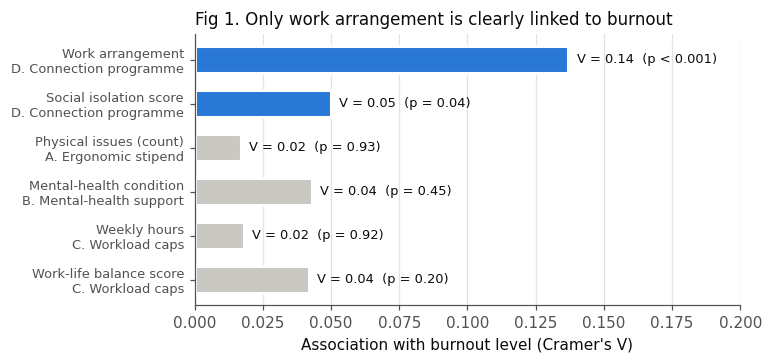

In [8]:
# Figure 1 - Driver screen: strength of each factor's link to burnout
s = screen.iloc[::-1]
fig, ax = plt.subplots(figsize=(6.4, 3.2))
y = np.arange(len(s))
cols = ["#2a78d6" if sig else PALE for sig in s["Significant (p<0.05)"]]
ax.barh(y, s["Cramers_V"], color=cols, height=0.6, edgecolor="white", linewidth=2)
for yi, (v, p) in enumerate(zip(s["Cramers_V"], s["p"])):
    ptxt = "p < 0.001" if p < 0.001 else f"p = {p:.2f}"
    ax.text(v + 0.003, yi, f"V = {v:.2f}  ({ptxt})", va="center", fontsize=8.5, color=INK)
ax.set_yticks(y, [f"{f}\n{pr}" for f, pr in zip(s["Factor"], s["Proposal"])], fontsize=8.5)
ax.set_xlim(0, 0.2); ax.grid(axis="y", visible=False)
ax.set_xlabel("Association with burnout level (Cramer's V)")
ax.set_title("Fig 1. Only work arrangement is clearly linked to burnout", loc="left", fontsize=11, color=INK)
fig.savefig("outputs/fig1_driver_screen.png"); plt.show()

**Interpretation.** Work arrangement is the only factor with a clear link to burnout (V = 0.14, p < 0.001). Isolation is
only marginal (p = 0.04, V = 0.05). Physical issues, mental-health condition, hours and work-life balance show no link.
Sections 5-8 test each proposal's assumption in full.

## 5. Proposal A - Ergonomic home-office stipend

The stipend only reduces burnout if (a) home-based staff report more physical pain than onsite staff, and (b) physical pain
is linked to burnout. Both parts are tested.

In [9]:
# (a) Is each physical issue more common for hybrid/remote staff? Chi-square per issue, Bonferroni for 5 tests
rows = []
for c in ["PH_Eye_Strain", "PH_Back_Pain", "PH_Shoulder_Pain", "PH_Neck_Pain", "PH_Wrist_Pain"]:
    rates = df.groupby("Work_Arrangement", observed=True)[c].mean().mul(100).round(1)
    _, _, p, _ = cramers_v("Work_Arrangement", c, df)
    rows.append([c.replace("PH_", "").replace("_", " "), *rates, round(p, 3), round(min(p * 5, 1), 3)])
phys_arr = pd.DataFrame(rows, columns=["Issue", *[f"{a} %" for a in ORDER], "p", "p_bonferroni"])
p_count = stats.kruskal(*[g["Physical_Issue_Count"] for _, g in df.groupby("Work_Arrangement", observed=True)]).pvalue
print("Mean number of issues:", df.groupby("Work_Arrangement", observed=True)["Physical_Issue_Count"].mean().round(2).to_dict(),
      f"| Kruskal-Wallis p = {p_count:.3f}")
RESULTS.update(p_issue_count_by_arr=round(p_count, 2),
               neck_pain=phys_arr.set_index("Issue").loc["Neck Pain"].to_dict())
phys_arr

Mean number of issues: {'Onsite': 1.88, 'Hybrid': 1.85, 'Remote': 1.94} | Kruskal-Wallis p = 0.266


,Issue,Onsite %,Hybrid %,Remote %,p,p_bonferroni
0,Eye Strain,50.6,50.8,51.2,0.974,1.000
1,Back Pain,49.8,48.5,50.5,0.693,1.000
2,Shoulder Pain,47.1,49.4,46.6,0.449,1.000
3,Neck Pain,25.5,22.7,29.1,0.019,0.093
4,Wrist Pain,15.2,13.1,16.7,0.130,0.649


In [10]:
# (b) Is the number of physical issues linked to high burnout?
tab = df.groupby("Issue_Band")["High_Burnout"].agg(["mean", "size"]).rename(columns={"mean": "high_burnout_rate", "size": "n"})
tab["high_burnout_rate"] = (tab["high_burnout_rate"] * 100).round(1)
_, chi2, p, _ = cramers_v("Issue_Band", "High_Burnout", df)
print(tab, f"\n\nIssue band x high burnout: chi2 = {chi2:.1f}, p = {p:.3f}")
RESULTS["p_issues_x_highburnout"] = round(p, 2)
RESULTS["hb_by_issue_band"] = tab["high_burnout_rate"].to_dict()

            high_burnout_rate     n
Issue_Band                         
0                        31.8   280
1                        33.4   885
2                        33.2  1144
3+                       33.1   848 

Issue band x high burnout: chi2 = 0.3, p = 0.965


**Verdict on A - assumption fails.** Physical complaints are equally common in all three groups (about 1.9 issues each, p = 0.27),
and the high-burnout rate is flat at about 32-33% whatever the number of issues. Only neck pain is slightly higher for remote staff,
and that difference disappears after correcting for five tests. An ergonomic stipend may be justified on health-and-safety grounds,
but the data gives no reason to fund it **as a burnout intervention**.

## 6. Proposal B - Expanded mental-health support as a burnout measure

In [11]:
mh = pd.crosstab(df["Mental_Health_Status"], df["Burnout_Level"], normalize="index").mul(100).round(1)
mh["n"] = df["Mental_Health_Status"].value_counts()
v, chi2, p, dof = cramers_v("Mental_Health_Status", "Burnout_Level", df)
print(mh.sort_values("High", ascending=False))
print(f"\nCondition x burnout level: chi2 = {chi2:.1f}, df = {dof}, p = {p:.3f}, V = {v:.3f}")
any_rate = df.groupby("Any_MH_Condition")["High_Burnout"].mean().mul(100).round(1)
_, _, p_any, _ = cramers_v("Any_MH_Condition", "High_Burnout", df)
print(f"High burnout: no condition {any_rate[0]}% vs any condition {any_rate[1]}% (p = {p_any:.2f})")
_, _, p_mh_arr, _ = cramers_v("Work_Arrangement", "Any_MH_Condition", df)
print("Share with any condition by arrangement:",
      df.groupby("Work_Arrangement", observed=True)["Any_MH_Condition"].mean().mul(100).round(1).to_dict(), f"(p = {p_mh_arr:.2f})")
RESULTS.update(p_mh_x_burnout=round(p, 2), hb_no_condition=any_rate[0], hb_any_condition=any_rate[1],
               p_any_mh=round(p_any, 2), pct_any_mh=round(df["Any_MH_Condition"].mean() * 100, 1))

Burnout_Level          Low  Medium  High    n
Mental_Health_Status                         
None reported         22.5    42.6  34.9  799
Anxiety               23.4    42.1  34.5  394
Stress Disorder       19.8    46.0  34.1  378
PTSD                  25.1    41.8  33.1  423
Depression            22.8    45.1  32.1  386
ADHD                  28.3    40.8  30.9  385
Burnout               24.2    45.4  30.4  392

Condition x burnout level: chi2 = 11.9, df = 12, p = 0.455, V = 0.043
High burnout: no condition 34.9% vs any condition 32.5% (p = 0.23)
Share with any condition by arrangement: {'Onsite': 76.4, 'Hybrid': 73.4, 'Remote': 72.3} (p = 0.07)


**Verdict on B - assumption fails for burnout.** 75% of staff report a mental-health condition, but high burnout is no more common
among them (32.5%) than among staff with none (34.9%; p = 0.23), and no single condition stands out (p = 0.45).
Burnout is a work-related state, distinct from a clinical condition (Maslach & Leiter, 2016). Existing mental-health support should
stay as a duty of care, but extra money for it would not target burnout.

## 7. Proposal C - Workload caps

In [12]:
rows = []
for col, label in [("Hours_Band", "Weekly hours band"), ("Work_Life_Balance_Score", "Work-life balance score")]:
    rate = df.groupby(col, observed=True)["High_Burnout"].mean().mul(100).round(1).to_dict()
    _, chi2, p, _ = cramers_v(col, "High_Burnout", df)
    rows.append([label, rate, round(chi2, 1), round(p, 2)])
    print(f"{label}: high burnout % = {rate}, chi2 = {chi2:.1f}, p = {p:.2f}")
rho_h, p_rh = stats.spearmanr(df["Hours_Per_Week"], df["Burnout_Score"])
rho_w, p_rw = stats.spearmanr(df["Work_Life_Balance_Score"], df["Burnout_Score"])
print(f"\nSpearman: hours vs burnout rho = {rho_h:.3f} (p = {p_rh:.2f}); work-life balance vs burnout rho = {rho_w:.3f} (p = {p_rw:.2f})")
RESULTS.update(rho_hours=round(rho_h, 3), p_rho_hours=round(p_rh, 2), rho_wlb=round(rho_w, 3), p_rho_wlb=round(p_rw, 2),
               hb_hours_band=df.groupby("Hours_Band", observed=True)["High_Burnout"].mean().mul(100).round(1).to_dict())

Weekly hours band: high burnout % = {'35-40': 34.5, '41-50': 32.4, '51-60': 32.4, '61-65': 34.6}, chi2 = 1.5, p = 0.68
Work-life balance score: high burnout % = {1: 32.4, 2: 33.7, 3: 33.8, 4: 32.1, 5: 32.8}, chi2 = 0.8, p = 0.94

Spearman: hours vs burnout rho = -0.012 (p = 0.51); work-life balance vs burnout rho = -0.017 (p = 0.33)


**Verdict on C - assumption fails in this data.** Staff working 61-65 hours have the same high-burnout rate (35%) as those working
35-40 hours (35%), and work-life balance shows no relationship either. This contradicts a large body of research in which workload is a
core cause of burnout (Bakker & Demerouti, 2007), so it is treated with caution (see Section 11). On this evidence, though, hour caps
would not reduce burnout here.

## 8. Proposal D - Connection programme for staff working away from the office

In [13]:
ct = pd.crosstab(df["Work_Arrangement"], df["Burnout_Level"])
ct_pct = pd.crosstab(df["Work_Arrangement"], df["Burnout_Level"], normalize="index").mul(100).round(1)
v_arr, chi2, p, dof = cramers_v("Work_Arrangement", "Burnout_Level", df)
print(ct_pct, "\n")
print(f"Chi-square = {chi2:.1f}, df = {dof}, p = {p:.2e}, Cramer's V = {v_arr:.3f}")
print("\nPairwise test of High-burnout share (Bonferroni, 3 tests):")
for a, b in [("Onsite", "Hybrid"), ("Onsite", "Remote"), ("Hybrid", "Remote")]:
    sub = df[df["Work_Arrangement"].isin([a, b])]
    t = pd.crosstab(sub["Work_Arrangement"].astype(str), sub["High_Burnout"])
    c2, pp, _, _ = stats.chi2_contingency(t)
    print(f"  {a} vs {b}: chi2 = {c2:.1f}, adjusted p = {min(pp * 3, 1):.2e}")
hb = df.groupby("Work_Arrangement", observed=True)["High_Burnout"].mean().mul(100).round(1)
RESULTS.update(chi2_arr=round(chi2, 1), v_arr=round(v_arr, 2), hb_by_arr=hb.to_dict())

Burnout_Level      Low  Medium  High
Work_Arrangement                    
Onsite            30.2    43.4  26.4
Hybrid            19.2    45.1  35.7
Remote            13.8    39.8  46.4 

Chi-square = 117.9, df = 4, p = 1.54e-24, Cramer's V = 0.137

Pairwise test of High-burnout share (Bonferroni, 3 tests):
  Onsite vs Hybrid: chi2 = 24.8, adjusted p = 1.92e-06
  Onsite vs Remote: chi2 = 77.6, adjusted p = 3.71e-18
  Hybrid vs Remote: chi2 = 17.2, adjusted p = 9.87e-05


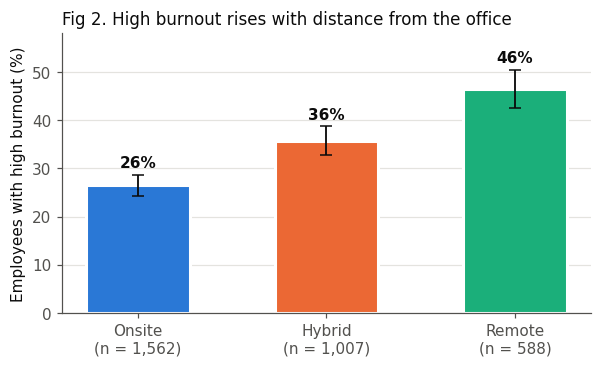

In [14]:
# Figure 2 - High-burnout rate by arrangement with 95% Wilson confidence intervals
rate = df.groupby("Work_Arrangement", observed=True)["High_Burnout"].agg(["mean", "sum", "size"])
lo, hi = proportion_confint(rate["sum"], rate["size"], method="wilson")
fig, ax = plt.subplots(figsize=(6.2, 3.3))
x = np.arange(3)
ax.bar(x, rate["mean"] * 100, width=0.55, color=[COLORS[k] for k in ORDER], edgecolor="white", linewidth=2)
ax.errorbar(x, rate["mean"] * 100, yerr=[(rate["mean"] - lo) * 100, (hi - rate["mean"]) * 100],
            fmt="none", ecolor=INK, elinewidth=1.2, capsize=4)
for i, k in enumerate(ORDER):
    ax.text(i, hi.iloc[i] * 100 + 1.5, f"{rate['mean'].iloc[i]*100:.0f}%", ha="center", color=INK, fontweight="bold")
ax.set_xticks(x, [f"{k}\n(n = {rate['size'].iloc[i]:,})" for i, k in enumerate(ORDER)])
ax.set_ylabel("Employees with high burnout (%)")
ax.set_ylim(0, 58); ax.grid(axis="x", visible=False)
ax.set_title("Fig 2. High burnout rises with distance from the office", loc="left", fontsize=11, color=INK)
fig.savefig("outputs/fig2_high_burnout_by_arrangement.png"); plt.show()

In [15]:
# Isolation by arrangement (Kruskal-Wallis on the 1-5 score, epsilon-squared effect size)
h, p = stats.kruskal(*[g["Social_Isolation_Score"] for _, g in df.groupby("Work_Arrangement", observed=True)])
eps2 = (h - 3 + 1) / (len(df) - 3)
iso_mean = df.groupby("Work_Arrangement", observed=True)["Social_Isolation_Score"].mean().round(2)
iso_high = df.groupby("Work_Arrangement", observed=True)["High_Isolation"].mean().mul(100).round(1)
print("Mean isolation:", iso_mean.to_dict(), f"| H = {h:.1f}, p = {p:.2e}, epsilon2 = {eps2:.3f}")
print("High isolation (4-5) %:", iso_high.to_dict())
for a, b in [("Onsite", "Hybrid"), ("Onsite", "Remote"), ("Hybrid", "Remote")]:
    _, pp = stats.mannwhitneyu(df.loc[df.Work_Arrangement == a, "Social_Isolation_Score"],
                               df.loc[df.Work_Arrangement == b, "Social_Isolation_Score"])
    print(f"  Isolation {a} vs {b}: adjusted p = {min(pp * 3, 1):.2e}")
RESULTS.update(iso_H=round(h, 1), iso_eps2=round(eps2, 2), iso_high_by_arr=iso_high.to_dict())

Mean isolation: {'Onsite': 2.38, 'Hybrid': 2.75, 'Remote': 3.5} | H = 382.4, p = 9.08e-84, epsilon2 = 0.121
High isolation (4-5) %: {'Onsite': 14.7, 'Hybrid': 25.0, 'Remote': 54.3}
  Isolation Onsite vs Hybrid: adjusted p = 1.90e-18
  Isolation Onsite vs Remote: adjusted p = 3.11e-78
  Isolation Hybrid vs Remote: adjusted p = 2.04e-35


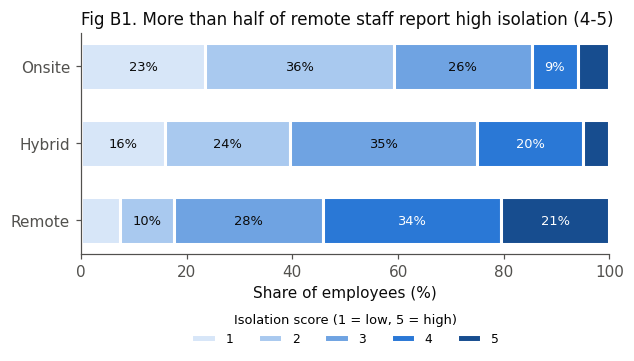

In [16]:
# Figure B1 (appendix) - Isolation score distribution by arrangement (100% stacked)
iso = pd.crosstab(df["Work_Arrangement"], df["Social_Isolation_Score"], normalize="index") * 100
blues = ["#d7e6f8", "#a9c9ef", "#6fa3e2", "#2a78d6", "#174d8f"]    # sequential: one hue, light -> dark
fig, ax = plt.subplots(figsize=(6.2, 2.6))
left = np.zeros(3)
for sc, col in zip(iso.columns, blues):
    ax.barh(ORDER, iso[sc], left=left, color=col, edgecolor="white", linewidth=2, label=str(sc), height=0.6)
    for i, v in enumerate(iso[sc]):
        if v >= 8:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if sc >= 4 else INK)
    left += iso[sc].values
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(False)
ax.set_xlabel("Share of employees (%)")
ax.legend(title="Isolation score (1 = low, 5 = high)", ncol=5, frameon=False, fontsize=8, title_fontsize=8.5,
          loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax.set_title("Fig B1. More than half of remote staff report high isolation (4-5)", loc="left", fontsize=11, color=INK)
fig.savefig("outputs/figB1_isolation_by_arrangement.png"); plt.show()

**Verdict on D - assumption holds.** High burnout rises from 26% onsite to 36% hybrid and 46% remote; every pair differs
(Bonferroni p < 0.001). Isolation follows the same order: 54% of remote staff report high isolation against 15% onsite
(epsilon-squared = 0.12, a medium effect). This is the only proposal whose target group is visible in the data.

## 9. All four levers together (multivariable logistic regression)

Each lever is now entered in one model, with demographics as controls. If a lever matters, its odds ratio (OR) sits clearly away from 1.
Hours are scaled per 10 hours so the effect is readable.

In [17]:
d = df.assign(Work_Arrangement=df["Work_Arrangement"].astype(str),
              Salary_Range=df["Salary_Range"].astype(str),
              Hours_10=df["Hours_Per_Week"] / 10)
LEVERS = ("C(Work_Arrangement, Treatment('Onsite')) + Social_Isolation_Score"     # D
          " + Physical_Issue_Count"                                               # A
          " + Any_MH_Condition"                                                   # B
          " + Hours_10 + Work_Life_Balance_Score")                                # C
CONTROLS = " + Age + C(Gender) + C(Industry) + C(Region) + C(Salary_Range)"
full = smf.logit("High_Burnout ~ " + LEVERS + CONTROLS, d).fit(disp=0)

def lr_test(drop_terms):
    # Likelihood-ratio test: does a block of terms add explanatory power beyond everything else?
    f = "High_Burnout ~ " + LEVERS + CONTROLS
    for t in drop_terms:
        f = f.replace(t, "")
    f = f.replace("~  + ", "~ ").replace("+  +", "+")
    red = smf.logit(f, d).fit(disp=0)
    stat = 2 * (full.llf - red.llf); k = full.df_model - red.df_model
    return round(stat, 1), int(k), stats.chi2.sf(stat, k)

blocks = {
    "D. Work arrangement": ["C(Work_Arrangement, Treatment('Onsite')) + "],
    "A. Physical issues": [" + Physical_Issue_Count"],
    "B. Mental-health condition": [" + Any_MH_Condition"],
    "C. Hours + work-life balance": [" + Hours_10", " + Work_Life_Balance_Score"],
}
lr_rows = [[k, *lr_test(v)] for k, v in blocks.items()]
lr_tab = pd.DataFrame(lr_rows, columns=["Lever", "LR chi2", "df", "p"])
auc = roc_auc_score(d["High_Burnout"], full.predict(d))
print(f"McFadden pseudo-R2 = {full.prsquared:.3f};  AUC = {auc:.3f}\n")
print(lr_tab.assign(p=lr_tab["p"].map(lambda x: f"{x:.2e}" if x < 0.001 else f"{x:.2f}")))

ors = pd.DataFrame({"OR": np.exp(full.params), "CI_low": np.exp(full.conf_int()[0]),
                    "CI_high": np.exp(full.conf_int()[1]), "p": full.pvalues}).round(3)
KEY = ["C(Work_Arrangement, Treatment('Onsite'))[T.Hybrid]", "C(Work_Arrangement, Treatment('Onsite'))[T.Remote]",
       "Social_Isolation_Score", "Physical_Issue_Count", "Any_MH_Condition", "Hours_10", "Work_Life_Balance_Score"]
RESULTS.update(pseudo_r2=round(full.prsquared, 3), auc=round(auc, 2),
               lr=lr_tab.set_index("Lever")["p"].to_dict(),
               ors={k: ors.loc[k].to_dict() for k in KEY})
ors.loc[KEY]

McFadden pseudo-R2 = 0.025;  AUC = 0.605

                          Lever  LR chi2  df         p
0           D. Work arrangement     68.5   2  1.37e-15
1            A. Physical issues      0.2   1      0.66
2    B. Mental-health condition      1.0   1      0.33
3  C. Hours + work-life balance      0.1   2      0.93


,OR,CI_low,CI_high,p
"C(Work_Arrangement, Treatment('Onsite'))[T.Hybrid]",1.555,1.301,1.859,0.000
"C(Work_Arrangement, Treatment('Onsite'))[T.Remote]",2.498,2.001,3.118,0.000
Social_Isolation_Score,0.961,0.898,1.029,0.256
Physical_Issue_Count,1.016,0.946,1.092,0.655
Any_MH_Condition,0.917,0.771,1.090,0.325
Hours_10,0.984,0.904,1.071,0.708
Work_Life_Balance_Score,0.998,0.935,1.066,0.961


In [18]:
# Adjusted probability of high burnout in each arrangement, all else held as observed
pred = {a: full.predict(d.assign(Work_Arrangement=a)).mean() for a in ORDER}
print("Adjusted probability of high burnout:", {a: f"{v*100:.1f}%" for a, v in pred.items()})
RESULTS["adj_prob"] = {a: round(v * 100, 1) for a, v in pred.items()}

# Robustness check: ordinal logistic model on all three burnout levels (Low < Medium < High)
X = pd.get_dummies(d["Work_Arrangement"])[["Hybrid", "Remote"]]
X = X.join(d[["Social_Isolation_Score", "Physical_Issue_Count", "Any_MH_Condition", "Hours_10", "Work_Life_Balance_Score", "Age"]]).astype(float)
om = OrderedModel(df["Burnout_Score"], X, distr="logit").fit(method="bfgs", disp=0)
ord_tab = pd.DataFrame({"OR": np.exp(om.params[:7]), "p": om.pvalues[:7]}).round(3)
RESULTS["ordinal_or"] = ord_tab["OR"].to_dict()
print(ord_tab)

Adjusted probability of high burnout: {'Onsite': '26.3%', 'Hybrid': '35.7%', 'Remote': '47.0%'}
                            OR      p
Hybrid                   1.678  0.000
Remote                   2.634  0.000
Social_Isolation_Score   0.961  0.190
Physical_Issue_Count     1.012  0.707
Any_MH_Condition         0.940  0.422
Hours_10                 0.975  0.494
Work_Life_Balance_Score  0.978  0.445


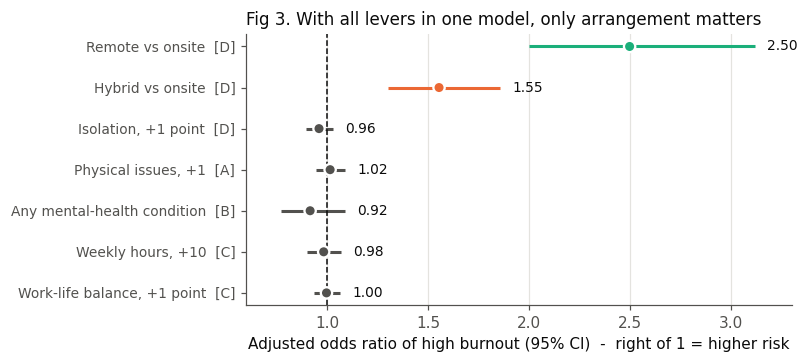

In [19]:
# Figure 3 - Adjusted odds ratios for each lever (forest plot)
labels = {"C(Work_Arrangement, Treatment('Onsite'))[T.Remote]": "Remote vs onsite  [D]",
          "C(Work_Arrangement, Treatment('Onsite'))[T.Hybrid]": "Hybrid vs onsite  [D]",
          "Social_Isolation_Score": "Isolation, +1 point  [D]",
          "Physical_Issue_Count": "Physical issues, +1  [A]",
          "Any_MH_Condition": "Any mental-health condition  [B]",
          "Hours_10": "Weekly hours, +10  [C]",
          "Work_Life_Balance_Score": "Work-life balance, +1 point  [C]"}
fp = ors.loc[list(labels)].rename(index=labels).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.4, 3.2))
y = np.arange(len(fp))
col = [COLORS["Remote"] if i.startswith("Remote") else COLORS["Hybrid"] if i.startswith("Hybrid") else MUTED for i in fp.index]
ax.hlines(y, fp["CI_low"], fp["CI_high"], color=col, linewidth=2)
ax.scatter(fp["OR"], y, color=col, s=55, zorder=3, edgecolor="white", linewidth=1.5)
ax.axvline(1, color=INK, linewidth=1, linestyle="--")
for yi, (o, h) in enumerate(zip(fp["OR"], fp["CI_high"])):
    ax.text(h + 0.06, yi, f"{o:.2f}", va="center", fontsize=9, color=INK)
ax.set_yticks(y, fp.index, fontsize=9); ax.grid(axis="y", visible=False)
ax.set_xlabel("Adjusted odds ratio of high burnout (95% CI)  -  right of 1 = higher risk")
ax.set_xlim(0.6, 3.3)
ax.set_title("Fig 3. With all levers in one model, only arrangement matters", loc="left", fontsize=11, color=INK)
fig.savefig("outputs/fig3_lever_odds_ratios.png"); plt.show()

**Interpretation.** Holding every other lever and demographic constant, remote staff have about 2.5x the odds of high burnout and
hybrid staff about 1.6x, compared with onsite staff (adjusted probability 26% / 36% / 47%). Physical issues, mental-health condition,
hours and work-life balance all sit on 1 (no effect), and their likelihood-ratio tests are not significant. The ordinal model agrees.

Two cautions shape how the budget is spent:
1. **Low predictive power** (pseudo-R2 = 0.03, AUC = 0.61): arrangement shifts risk across a *group*, but cannot pick out which
   *individual* will burn out. So the programme should be offered to whole groups, not to individuals screened by a model.
2. **Isolation is not the pathway in this data.** It differs sharply by arrangement (Section 8), but has no independent effect on burnout
   once arrangement is in the model. The data shows *who* to target (remote, then hybrid staff), not *why* they burn out. The programme
   design therefore leans on published research and must be piloted and measured.

## 10. Targeting and sizing the connection programme

In [20]:
# Is the arrangement effect the same in every industry? (decides one firm-wide programme vs industry-specific ones)
inter = smf.logit("High_Burnout ~ C(Work_Arrangement) * C(Industry)", d).fit(disp=0)
main = smf.logit("High_Burnout ~ C(Work_Arrangement) + C(Industry)", d).fit(disp=0)
lr_i = 2 * (inter.llf - main.llf); df_i = inter.df_model - main.df_model
p_i = stats.chi2.sf(lr_i, df_i)
heat = df.pivot_table(index="Industry", columns="Work_Arrangement", values="High_Burnout",
                      aggfunc="mean", observed=True).mul(100)
heat["Remote gap (pts)"] = heat["Remote"] - heat["Onsite"]
heat = heat.sort_values("Remote gap (pts)", ascending=False)
n_pos = int((heat["Remote gap (pts)"] > 0).sum())
print(f"Arrangement x industry interaction: chi2 = {lr_i:.1f}, df = {df_i:.0f}, p = {p_i:.2f}")
print(f"Remote gap > 0 in {n_pos} of {len(heat)} industries")
RESULTS.update(p_interaction=round(p_i, 2), n_industries_gap_pos=n_pos,
               gap_range=[round(heat["Remote gap (pts)"].min(), 1), round(heat["Remote gap (pts)"].max(), 1)])
heat.round(1)

Arrangement x industry interaction: chi2 = 17.0, df = 16, p = 0.39
Remote gap > 0 in 9 of 9 industries


Work_Arrangement,Onsite,Hybrid,Remote,Remote gap (pts)
Industry,,,,
Marketing,28.6,40.6,63.2,34.6
Technology,26.1,36.7,51.0,24.9
Healthcare,29.2,37.5,51.6,22.4
Professional Services,27.1,32.5,47.4,20.2
Finance,29.5,33.7,49.1,19.5
Education,21.8,31.0,39.1,17.4
Manufacturing,22.2,37.9,36.7,14.4
Customer Service,30.6,27.1,44.4,13.8
Retail,21.1,48.1,33.3,12.2


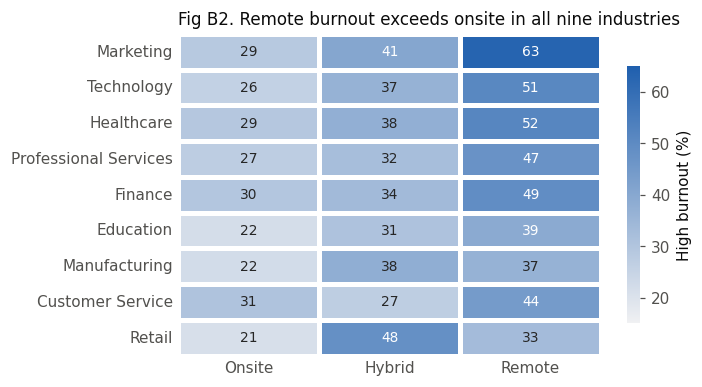

In [21]:
# Figure B2 (appendix) - Heatmap of high-burnout rate, industry x arrangement
fig, ax = plt.subplots(figsize=(6.2, 3.8))
sns.heatmap(heat[ORDER], annot=True, fmt=".0f", cmap=sns.light_palette("#1f5fae", as_cmap=True),
            vmin=15, vmax=65, linewidths=2, linecolor="white",
            cbar_kws={"label": "High burnout (%)", "shrink": 0.8}, ax=ax, annot_kws={"fontsize": 9})
ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(length=0)
ax.set_title("Fig B2. Remote burnout exceeds onsite in all nine industries", loc="left", fontsize=11, color=INK)
fig.savefig("outputs/figB2_industry_heatmap.png"); plt.show()

In [22]:
# Sizing: how many high-burnout cases sit above the onsite baseline? (the most the programme could address)
base = df.loc[df.Work_Arrangement == "Onsite", "High_Burnout"].mean()
size = df.groupby("Work_Arrangement", observed=True).agg(n=("High_Burnout", "size"), high=("High_Burnout", "sum"))
size["rate_%"] = (size["high"] / size["n"] * 100).round(1)
size["excess_vs_onsite"] = size["high"] - size["n"] * base          # unrounded, so the total is exact
excess = round(size.loc[["Hybrid", "Remote"], "excess_vs_onsite"].sum())
in_scope = size.loc[["Hybrid", "Remote"], "n"].sum()
print(size.round(1))
print(f"\nIn scope (hybrid + remote): {in_scope:,} staff ({in_scope/len(df)*100:.0f}% of workforce)")
print(f"Excess high-burnout cases vs onsite rate: {excess:.0f} of {df.High_Burnout.sum():,} ({excess/df.High_Burnout.sum()*100:.0f}%)")
RESULTS.update(in_scope=int(in_scope), in_scope_pct=round(in_scope / len(df) * 100), excess=int(excess),
               excess_remote=round(size.loc["Remote", "excess_vs_onsite"]), excess_hybrid=round(size.loc["Hybrid", "excess_vs_onsite"]),
               total_high=int(df.High_Burnout.sum()), excess_pct=round(excess / df.High_Burnout.sum() * 100))

                     n  high  rate_%  excess_vs_onsite
Work_Arrangement                                      
Onsite            1562   413    26.4               0.0
Hybrid            1007   360    35.7              93.7
Remote             588   273    46.4             117.5

In scope (hybrid + remote): 1,595 staff (51% of workforce)
Excess high-burnout cases vs onsite rate: 211 of 1,046 (20%)


**Interpretation.** The remote gap appears in all nine industries and the interaction is not significant, so one firm-wide programme
fits; no industry needs its own version. Hybrid and remote staff are about half the workforce. If their high-burnout rate fell to the
onsite level, about 211 fewer employees would be highly burnt out - roughly a fifth of all high-burnout cases. That is a **ceiling**, not a
forecast: it assumes the whole gap is caused by arrangement and that the programme closes it fully.

## 11. Summary - from evidence to budget decision

In [23]:
scorecard = pd.DataFrame([
    ["A. Ergonomic stipend", "Pain higher off-site and linked to burnout",
     "Same pain in all groups (p = 0.27); burnout flat across issue counts (p = 0.93)", "Not as a burnout measure"],
    ["B. Mental-health support", "People with a condition burn out more",
     "32.5% vs 34.9% high burnout (p = 0.23); no condition stands out (p = 0.45)", "Keep current level; no new burnout money"],
    ["C. Workload caps", "Long hours / poor balance drive burnout",
     "Same burnout at 35-40 h and 61-65 h (p = 0.92); balance not linked (p = 0.20)", "Not on this evidence"],
    ["D. Connection programme", "Burnout and isolation concentrate off-site",
     "26% / 36% / 46% high burnout; adjusted OR 2.5 remote; 54% remote highly isolated", "Fund - remote first, then hybrid; pilot"],
], columns=["Proposal", "Assumption", "Evidence", "Budget decision"])
with open("outputs/key_results.json", "w") as f:
    json.dump(RESULTS, f, indent=1, default=str)
scorecard

,Proposal,Assumption,Evidence,Budget decision
0,A. Ergonomic stipend,Pain higher off-site and linked to burnout,Same pain in all groups (p = 0.27); burnout fl...,Not as a burnout measure
1,B. Mental-health support,People with a condition burn out more,32.5% vs 34.9% high burnout (p = 0.23); no con...,Keep current level; no new burnout money
2,C. Workload caps,Long hours / poor balance drive burnout,Same burnout at 35-40 h and 61-65 h (p = 0.92)...,Not on this evidence
3,D. Connection programme,Burnout and isolation concentrate off-site,26% / 36% / 46% high burnout; adjusted OR 2.5 ...,"Fund - remote first, then hybrid; pilot"


**Limits to keep in view:** the survey is a single snapshot (association, not causation); burnout is one self-rated item; and the data
contradicts well-established findings (hours unrelated to burnout), which suggests it may be synthetic. The recommendation is therefore
framed as a **funded pilot with measurement**, not a permanent commitment.